# 02 — Modelling: LightGBM vs Logistic Regression
**Objective 2 of the proposal:** train and validate a fraud detection model, benchmarking an interpretable baseline (logistic regression) against a gradient-boosted ensemble (LightGBM).

**Run `1_EDA.ipynb` first** — this notebook loads the train/test sets it saved in `outputs/processed/`.

**Design**
| Data | Months | Used for |
|---|---|---|
| Training | 0–4 | Fitting both models |
| Validation | 5 | Hyperparameter tuning, early stopping, and choosing the decision threshold |
| Test | 6–7 | Final evaluation only — never used for any decision |

Both models are trained on the same months and use the same threshold rule, so the comparison is like for like. The decision threshold is set so that **5% of legitimate applicants in the validation month are flagged** (the BAF operating point). Applying that threshold to the test months shows how stable it is when the data drifts over time.

In [1]:
import os
import sys
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb

RANDOM_STATE = 42
TARGET_FPR = 0.05   # flag 5% of legitimate applicants (BAF operating point)

# ---- Work out where the data is, depending on which machine this is running on ----
COLAB_DATA_DIR = '/content/drive/MyDrive/Dissertation/data'   # edit to match your Drive folder

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path(COLAB_DATA_DIR)
    MACHINE = 'Google Colab'
elif os.environ.get('DISSERTATION_DATA_DIR'):
    DATA_DIR = Path(os.environ['DISSERTATION_DATA_DIR'])
    MACHINE = 'Local (DISSERTATION_DATA_DIR)'
else:
    here = Path.cwd().resolve()
    DATA_DIR = next(
        (p / 'data' for p in [here, *here.parents]
         if (p / 'data' / 'Base.csv').exists() or (p / 'data' / 'Base.parquet').exists()),
        None,
    )
    if DATA_DIR is None:
        raise FileNotFoundError(
            "Could not find data/Base.csv. Put it in a 'data' folder inside the repository, "
            "or set the DISSERTATION_DATA_DIR environment variable."
        )
    MACHINE = 'Local'

OUTPUT_DIR = DATA_DIR.parent / 'outputs'
PROCESSED_DIR = OUTPUT_DIR / 'processed'
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'
FIGURES_DIR = OUTPUT_DIR / 'figures'
for d in [PROCESSED_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Machine:    {MACHINE}")
print(f"Data dir:   {DATA_DIR}")
print(f"Output dir: {OUTPUT_DIR}")
print(f"pandas {pd.__version__} | LightGBM {lgb.__version__}")

Machine:    Local
Data dir:   /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/data
Output dir: /Users/lucy/Desktop/PROJ519 MSc Dissertation and Research Skills/analysis/outputs
pandas 3.0.6 | LightGBM 4.7.0


## Load the data saved by notebook 1

In [2]:
if not (PROCESSED_DIR / 'X_train.parquet').exists():
    raise FileNotFoundError("Processed data not found. Run 1_EDA.ipynb first.")

X_train_full = pd.read_parquet(PROCESSED_DIR / 'X_train.parquet')
X_test = pd.read_parquet(PROCESSED_DIR / 'X_test.parquet')
y_train_full = pd.read_parquet(PROCESSED_DIR / 'y_train.parquet').iloc[:, 0]
y_test = pd.read_parquet(PROCESSED_DIR / 'y_test.parquet').iloc[:, 0]

config = joblib.load(MODELS_DIR / 'feature_config.joblib')
FEATURES = config['FEATURES']
CAT_FEATURES = config['CAT_FEATURES']
NUM_FEATURES = config['NUM_FEATURES']
PROTECTED_ATTRIBUTES = config['PROTECTED_ATTRIBUTES']
SPLIT_METHOD = config['SPLIT_METHOD']

# Make sure test categories match training categories exactly (matters for LightGBM and SHAP)
for col in CAT_FEATURES:
    X_test[col] = X_test[col].astype('category').cat.set_categories(X_train_full[col].cat.categories)

print("Split method from notebook 1:", SPLIT_METHOD)
print("Train (months 0–5):", X_train_full.shape, f"| fraud rate {y_train_full.mean() * 100:.2f}%")
print("Test  (months 6–7):", X_test.shape, f"| fraud rate {y_test.mean() * 100:.2f}%")
print("Categorical features:", CAT_FEATURES)

Split method from notebook 1: temporal
Train (months 0–5): (794989, 29) | fraud rate 1.03%
Test  (months 6–7): (205011, 29) | fraud rate 1.40%
Categorical features: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']


## Validation set
With the temporal split, month 5 (the most recent training month) becomes the validation set, so tuning also respects time order. The `month` column was removed from the features in notebook 1, so it is looked up again from the original data using the row index.

In [3]:
if SPLIT_METHOD == 'temporal':
    months = pd.read_parquet(DATA_DIR / 'Base.parquet', columns=['month'])['month']
    train_months = months.loc[X_train_full.index]
    val_mask = (train_months == train_months.max()).to_numpy()
    del months, train_months
else:
    # Random split in notebook 1 -> use a stratified random 15% of the training set for validation
    from sklearn.model_selection import train_test_split
    tr_idx, va_idx = train_test_split(
        np.arange(len(X_train_full)), test_size=0.15,
        random_state=RANDOM_STATE, stratify=y_train_full,
    )
    val_mask = np.zeros(len(X_train_full), dtype=bool)
    val_mask[va_idx] = True

X_tr, y_tr = X_train_full[~val_mask], y_train_full[~val_mask]
X_val, y_val = X_train_full[val_mask], y_train_full[val_mask]
del X_train_full, y_train_full
gc.collect()

print("Training:  ", X_tr.shape, f"| fraud rate {y_tr.mean() * 100:.2f}%")
print("Validation:", X_val.shape, f"| fraud rate {y_val.mean() * 100:.2f}%")
print("Test:      ", X_test.shape, f"| fraud rate {y_test.mean() * 100:.2f}%")

Training:   (675666, 29) | fraud rate 1.00%
Validation: (119323, 29) | fraud rate 1.18%
Test:       (205011, 29) | fraud rate 1.40%


## Evaluation functions

In [4]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, roc_curve, precision_recall_curve, confusion_matrix,
)

def recall_at_fpr(y_true, y_prob, target_fpr=TARGET_FPR):
    """Highest recall achievable while keeping the false-positive rate at or below target_fpr
    (the BAF benchmark metric; the threshold is chosen on the same data it is measured on)."""
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return float(tpr[fpr <= target_fpr].max())

def threshold_at_fpr(y_true, y_prob, target_fpr=TARGET_FPR):
    """Score threshold that flags target_fpr of the legitimate cases."""
    legit_scores = np.asarray(y_prob)[np.asarray(y_true) == 0]
    return float(np.quantile(legit_scores, 1 - target_fpr))

def evaluate(name, y_true, y_prob, threshold):
    """Threshold-free metrics plus metrics at a fixed decision threshold."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'model': name,
        'AUC-ROC': roc_auc_score(y_true, y_prob),
        'AUC-PR': average_precision_score(y_true, y_prob),
        'Recall@5%FPR': recall_at_fpr(y_true, y_prob),
        'threshold': threshold,
        'FPR': fp / (fp + tn),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        'legit_flagged_per_fraud_caught': fp / tp if tp else np.nan,
    }

## Baseline: logistic regression (retrained on months 0–4)
Same pipeline as notebook 1 (scaling + one-hot encoding + balanced class weights), refitted on the same training months as LightGBM so the comparison is fair.

In [5]:
from sklearn.base import clone

lr_model = clone(joblib.load(MODELS_DIR / 'logistic_regression.joblib'))

start = time.time()
lr_model.fit(X_tr, y_tr)
lr_train_time = time.time() - start
print(f"Logistic regression trained in {lr_train_time:.1f} s")

lr_val_prob = lr_model.predict_proba(X_val)[:, 1]
lr_test_prob = lr_model.predict_proba(X_test)[:, 1]
lr_threshold = threshold_at_fpr(y_val, lr_val_prob)

print(f"Validation recall@5%FPR: {recall_at_fpr(y_val, lr_val_prob):.4f}")
print(f"Threshold chosen on validation month: {lr_threshold:.4f}")

Logistic regression trained in 2.7 s
Validation recall@5%FPR: 0.5004
Threshold chosen on validation month: 0.7207


## LightGBM: hyperparameter tuning
Random search over a small grid. Each candidate is trained on months 0–4 with **early stopping** on month 5 (training stops once validation AUC-PR stops improving), and candidates are ranked by **validation recall at 5% FPR**.

Candidates are trained one at a time on purpose, so memory stays low on an 8GB laptop. `scale_pos_weight` is part of the search, so the data decides whether class weighting helps.

`N_TRIALS = 20` takes roughly 10–20 minutes on a MacBook Air M1. On the university PC, 50+ trials are feasible.

In [6]:
from sklearn.model_selection import ParameterSampler

N_TRIALS = 20

imbalance_ratio = (y_tr == 0).sum() / (y_tr == 1).sum()

param_space = {
    'num_leaves': [15, 31, 63, 127],
    'min_child_samples': [20, 50, 100, 200, 500],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [0.0, 1.0, 5.0, 10.0],
    'scale_pos_weight': [1.0, 10.0, round(float(imbalance_ratio), 1)],
}
candidates = list(ParameterSampler(param_space, n_iter=N_TRIALS, random_state=RANDOM_STATE))

base_params = dict(
    objective='binary',
    learning_rate=0.05,
    n_estimators=3000,          # upper limit; early stopping picks the real number
    subsample_freq=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

# LightGBM 4.7+ uses eval_X/eval_y; older versions (e.g. on Colab) use eval_set
import inspect
if 'eval_X' in inspect.signature(lgb.LGBMClassifier.fit).parameters:
    eval_kwargs = {'eval_X': X_val, 'eval_y': y_val}
else:
    eval_kwargs = {'eval_set': [(X_val, y_val)]}

tuning_log = []
best_score, best_model, best_params = -np.inf, None, None
tuning_start = time.time()

for i, params in enumerate(candidates, start=1):
    start = time.time()
    model = lgb.LGBMClassifier(**base_params, **params)
    model.fit(
        X_tr, y_tr,
        **eval_kwargs,
        eval_metric='average_precision',
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    val_prob = model.predict_proba(X_val)[:, 1]
    score = recall_at_fpr(y_val, val_prob)
    tuning_log.append({
        'trial': i, **params,
        'best_iteration': model.best_iteration_,
        'val_AUC-PR': average_precision_score(y_val, val_prob),
        'val_Recall@5%FPR': score,
        'seconds': round(time.time() - start, 1),
    })
    print(f"Trial {i:2d}/{N_TRIALS}: val recall@5%FPR = {score:.4f} | "
          f"trees = {model.best_iteration_:4d} | {time.time() - start:5.1f} s")

    if score > best_score:
        best_score, best_model, best_params = score, model, params
    else:
        del model
    gc.collect()

print(f"\nTuning finished in {(time.time() - tuning_start) / 60:.1f} minutes")
print(f"Best validation recall@5%FPR: {best_score:.4f}")
print("Best parameters:", best_params, f"| trees = {best_model.best_iteration_}")

tuning_df = pd.DataFrame(tuning_log).sort_values('val_Recall@5%FPR', ascending=False)
tuning_df.to_csv(RESULTS_DIR / 'lightgbm_tuning.csv', index=False)
tuning_df.head(10)

Trial  1/20: val recall@5%FPR = 0.4380 | trees =    2 |   5.3 s
Trial  2/20: val recall@5%FPR = 0.3444 | trees =    1 |   5.6 s
Trial  3/20: val recall@5%FPR = 0.4302 | trees =    1 |   5.0 s
Trial  4/20: val recall@5%FPR = 0.2849 | trees =    1 |   3.9 s
Trial  5/20: val recall@5%FPR = 0.5450 | trees =  225 |   8.2 s
Trial  6/20: val recall@5%FPR = 0.2828 | trees =    1 |   2.7 s
Trial  7/20: val recall@5%FPR = 0.4486 | trees =    1 |   3.6 s
Trial  8/20: val recall@5%FPR = 0.2828 | trees =    1 |   3.3 s
Trial  9/20: val recall@5%FPR = 0.3182 | trees =    1 |   2.9 s
Trial 10/20: val recall@5%FPR = 0.5337 | trees =  111 |   9.7 s
Trial 11/20: val recall@5%FPR = 0.4479 | trees =    4 |   5.7 s
Trial 12/20: val recall@5%FPR = 0.5436 | trees =  171 |   9.1 s
Trial 13/20: val recall@5%FPR = 0.4366 | trees =    2 |   2.8 s
Trial 14/20: val recall@5%FPR = 0.4096 | trees =    1 |   3.5 s
Trial 15/20: val recall@5%FPR = 0.5528 | trees =  278 |   9.8 s
Trial 16/20: val recall@5%FPR = 0.5422 |

,trial,subsample,scale_pos_weight,reg_lambda,num_leaves,min_child_samples,colsample_bytree,best_iteration,val_AUC-PR,val_Recall@5%FPR,seconds
14,15,0.70,1.0,10.0,31,200,0.8,278,0.198047,0.552799,9.8
19,20,0.70,1.0,10.0,15,20,0.8,305,0.195909,0.545712,7.8
17,18,0.70,1.0,10.0,15,200,0.6,387,0.196536,0.545004,11.3
4,5,0.70,1.0,5.0,31,50,1.0,225,0.193974,0.545004,8.2
11,12,1.00,1.0,10.0,63,50,1.0,171,0.193296,0.543586,9.1
15,16,0.85,1.0,5.0,63,50,0.8,150,0.191638,0.542169,8.7
9,10,1.00,1.0,1.0,127,500,1.0,111,0.187068,0.533664,9.7
6,7,1.00,10.0,1.0,63,200,0.8,1,0.088604,0.448618,3.6
10,11,0.85,10.0,5.0,127,20,0.6,4,0.103464,0.447909,5.7
0,1,1.00,10.0,10.0,127,20,0.8,2,0.104126,0.437987,5.3


In [7]:
lgbm_model = best_model

lgbm_val_prob = lgbm_model.predict_proba(X_val)[:, 1]
lgbm_test_prob = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_threshold = threshold_at_fpr(y_val, lgbm_val_prob)

print(f"Threshold chosen on validation month: {lgbm_threshold:.4f}")

Threshold chosen on validation month: 0.0293


## Test-set comparison
- **Recall@5%FPR** is the BAF benchmark metric (threshold set on the test data itself), so it is comparable with published BAF results.
- **Precision, Recall, F1, FPR and the confusion-matrix counts** use the threshold chosen on the validation month — what would actually happen in deployment. If the test **FPR** drifts away from 5%, that shows the threshold is not stable over time.

In [8]:
results = pd.DataFrame([
    evaluate('Logistic Regression', y_test, lr_test_prob, lr_threshold),
    evaluate('LightGBM', y_test, lgbm_test_prob, lgbm_threshold),
]).set_index('model')

results.to_csv(RESULTS_DIR / 'model_comparison.csv')

display_cols = ['AUC-ROC', 'AUC-PR', 'Recall@5%FPR', 'FPR', 'Precision', 'Recall', 'F1',
                'TP', 'FP', 'FN', 'legit_flagged_per_fraud_caught']
results[display_cols].round(4)

,AUC-ROC,AUC-PR,Recall@5%FPR,FPR,Precision,Recall,F1,TP,FP,FN,legit_flagged_per_fraud_caught
model,,,,,,,,,,,
Logistic Regression,0.8757,0.1529,0.4896,0.0474,0.1261,0.4805,0.1998,1383,9586,1495,6.9313
LightGBM,0.8941,0.2001,0.5479,0.0603,0.1212,0.5837,0.2007,1680,12184,1198,7.2524


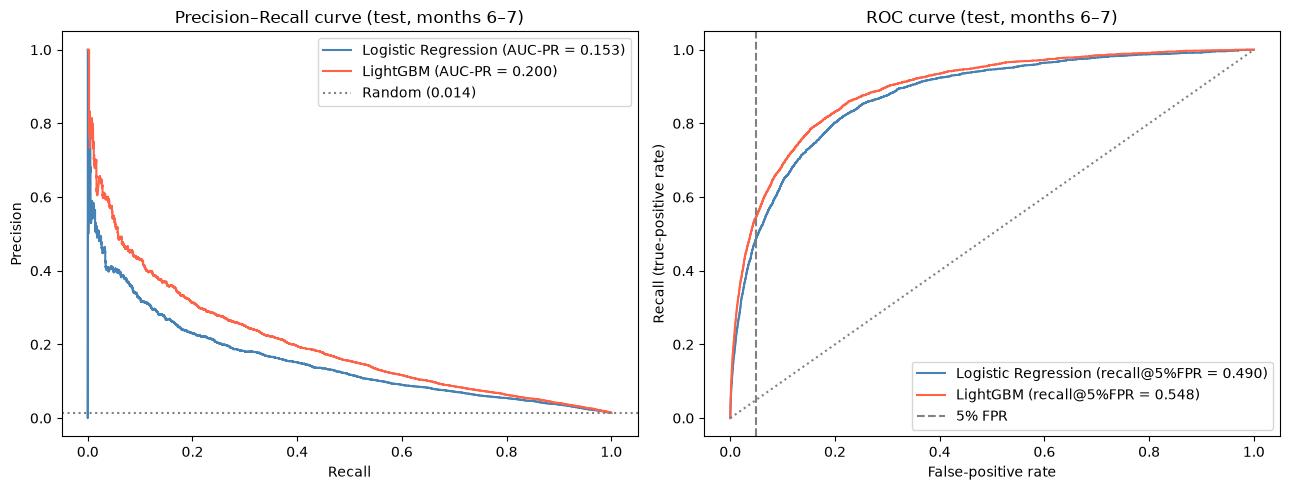

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob, colour in [('Logistic Regression', lr_test_prob, 'steelblue'),
                           ('LightGBM', lgbm_test_prob, 'tomato')]:
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(recall, precision, color=colour,
                 label=f"{name} (AUC-PR = {average_precision_score(y_test, prob):.3f})")
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, color=colour,
                 label=f"{name} (recall@5%FPR = {recall_at_fpr(y_test, prob):.3f})")

axes[0].axhline(y_test.mean(), color='grey', linestyle=':', label=f'Random ({y_test.mean():.3f})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision–Recall curve (test, months 6–7)')
axes[0].legend()

axes[1].axvline(TARGET_FPR, color='grey', linestyle='--', label='5% FPR')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle=':')
axes[1].set_xlabel('False-positive rate')
axes[1].set_ylabel('Recall (true-positive rate)')
axes[1].set_title('ROC curve (test, months 6–7)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'pr_roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

## LightGBM's built-in feature importance
A first look only. Gain-based importance is known to be biased and gives no direction of effect; the proper explanation is done with SHAP in notebook 3.

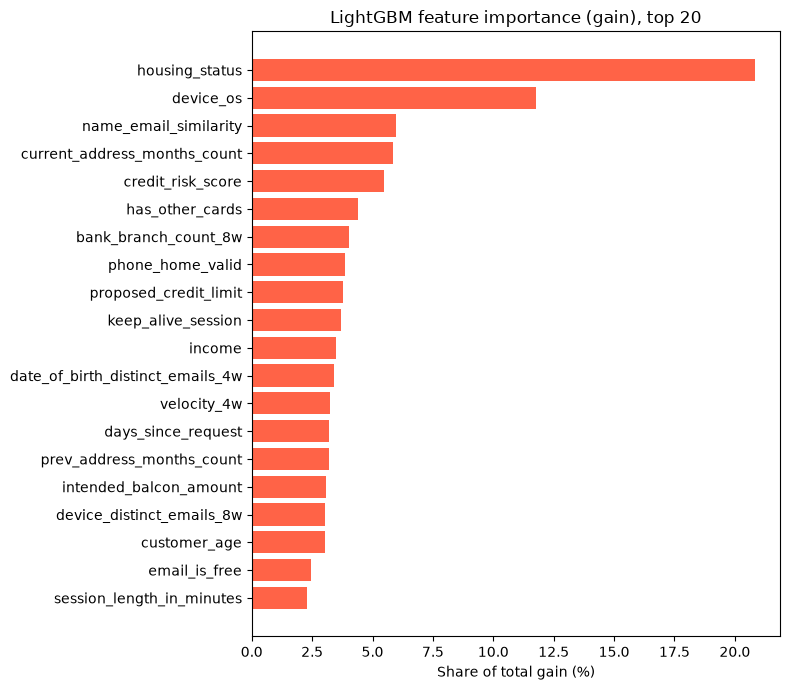

Protected attributes' rank (out of 29 features):
  customer_age: 18
  income: 11
  employment_status: 23


In [10]:
importance = pd.Series(
    lgbm_model.booster_.feature_importance(importance_type='gain'),
    index=lgbm_model.booster_.feature_name(),
).sort_values(ascending=True)

top = importance.tail(20)
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values / top.values.sum() * 100, color='tomato')
plt.xlabel('Share of total gain (%)')
plt.title('LightGBM feature importance (gain), top 20')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'lightgbm_gain_importance.png', dpi=200, bbox_inches='tight')
plt.show()

print("Protected attributes' rank (out of", len(importance), "features):")
ranks = importance.rank(ascending=False).astype(int)
for col in PROTECTED_ATTRIBUTES:
    if col in ranks:
        print(f"  {col}: {ranks[col]}")

## Save models and predictions for notebooks 3 (SHAP) and 4 (fairness)

In [11]:
joblib.dump(lgbm_model, MODELS_DIR / 'lightgbm.joblib')
joblib.dump(lr_model, MODELS_DIR / 'logistic_regression_m0-4.joblib')

with open(MODELS_DIR / 'thresholds.json', 'w') as f:
    json.dump({
        'target_fpr': TARGET_FPR,
        'chosen_on': 'validation month (month 5)' if SPLIT_METHOD == 'temporal' else 'random validation set',
        'Logistic Regression': lr_threshold,
        'LightGBM': lgbm_threshold,
        'lightgbm_params': {k: (float(v) if isinstance(v, (np.floating, float)) else v)
                            for k, v in best_params.items()},
        'lightgbm_trees': int(lgbm_model.best_iteration_),
    }, f, indent=2)

# Test-set scores and decisions, with the protected attributes, for the fairness audit
test_predictions = X_test[PROTECTED_ATTRIBUTES].copy()
test_predictions['fraud_bool'] = y_test.values
test_predictions['lr_score'] = lr_test_prob
test_predictions['lgbm_score'] = lgbm_test_prob
test_predictions['lr_flag'] = (lr_test_prob >= lr_threshold).astype(int)
test_predictions['lgbm_flag'] = (lgbm_test_prob >= lgbm_threshold).astype(int)
test_predictions.to_parquet(PROCESSED_DIR / 'test_predictions.parquet')

print("Saved:")
for p in [MODELS_DIR / 'lightgbm.joblib', MODELS_DIR / 'logistic_regression_m0-4.joblib',
          MODELS_DIR / 'thresholds.json', PROCESSED_DIR / 'test_predictions.parquet',
          RESULTS_DIR / 'model_comparison.csv', RESULTS_DIR / 'lightgbm_tuning.csv',
          FIGURES_DIR / 'pr_roc_curves.png', FIGURES_DIR / 'lightgbm_gain_importance.png']:
    print("  ", p.relative_to(OUTPUT_DIR.parent))

Saved:
   outputs/models/lightgbm.joblib
   outputs/models/logistic_regression_m0-4.joblib
   outputs/models/thresholds.json
   outputs/processed/test_predictions.parquet
   outputs/results/model_comparison.csv
   outputs/results/lightgbm_tuning.csv
   outputs/figures/pr_roc_curves.png
   outputs/figures/lightgbm_gain_importance.png
